# Layer sweeps — every encoder, every layer, every task

**Why this figure.** Every headline number in this project is one encoder at one layer. The layer is
picked by a rule: the best layer on call type (leave-birds-out folds), or the out-of-fold best arm
on in-distribution detection, frozen before BirdPark is scored. The findings keep warning, in prose,
that this choice is fragile: among a model's top three detection arms the selection criterion moves
20-98 times less than the holdout score it decides (046), the fold split moves call type as much as a training seed (062), and
three seeds of one recipe span about 0.02 (070). This notebook draws all of it so you can see it.

**How to read it.** One panel per task, depth on x, one line per encoder. Five reference encoders are
in colour; every other scored encoder is a thin grey line for context. Filled markers are the layer
each encoder is *reported* at; hollow markers are the other layers. For BirdPark the per-layer
values are for auditing only (detection_variants.json caveats): the reported value is the one at the
layer frozen on zebra finch, never the maximum over the curve.

**Depth axis.** Most encoders have 12 blocks. The 24-block BirdAVES-large models and the 4- and
6-block Whisper encoders are rescaled onto the same 0–11 axis (block *i* of *L* sits at
11·*i*/(*L*−1)), so "late" means the same thing for every line.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ANA = Path.home() / "zf_labelset/zf_detection_dataset_v1/analysis"
def load(name):
    p = ANA / name
    return json.loads(p.read_text()) if p.exists() else {}

# ---- call type, 11 classes, leave-birds-out: one value per layer
CT = {}
for m, v in load("aves_variants_calltype.json")["models"].items():
    CT[m] = dict(acc=list(v["per_layer_acc_11"]), best=v["best_11"]["layer"],
                 src="aves_variants_calltype.json")
SKIP = {"aves", "aves_variants", "finetune", "run15"}   # not per-layer frozen probes, or an alias
for p in sorted(ANA.glob("*_calltype.json")):
    tag = p.name[: -len("_calltype.json")]
    if tag in SKIP or tag in CT:
        continue
    j = json.loads(p.read_text())
    if "per_layer_acc11" in j:
        CT[tag] = dict(acc=list(j["per_layer_acc11"]), best=j["best_layer11"], src=p.name)
# run15's per-layer file is stored under its short name; the detection key is run15_combined
r15 = load("run15_calltype.json")
if r15:
    CT["run15_combined"] = dict(acc=r15["per_layer_acc11"], best=r15["best_layer11"],
                                src="run15_calltype.json")

# ---- detection: in-distribution ZF AUC and ZF->BirdPark AP, on each model's layer grid, at the
# normalisation ('matched' or 'native') that the pre-committed joint arm chose
D = load("detection_variants.json")
ROUND1_INTERMEDIATE = lambda k: k.startswith(("dapt5e5_step", "dapt1e4_step")) and not k.endswith("15000")
DET = {}
for m, pc in D["precommit"].items():
    if m == "logenergy" or ROUND1_INTERMEDIATE(m):
        continue
    tag = pc["joint"]["tag"]
    grid = D["layer_grids"][m]
    DET[m] = dict(tag=tag, layers=grid, chosen=pc["joint"]["layer"],
                  zf=[D["in_distribution"][m][f"{tag}_L{l}"]["auc"] for l in grid],
                  bp=[D["zf_to_bp"][m][f"{tag}_L{l}"]["ap"] for l in grid])
ENERGY_BP_AP = D["zf_to_bp"]["logenergy"]["L0"]["ap"]

def depth(n_layers):
    # rescale block index onto the 12-block axis
    return np.arange(n_layers) * 11 / (n_layers - 1)

print(f"call type: {len(CT)} encoders with per-layer scores")
print(f"detection: {len(DET)} encoders (round-1 DAPT intermediate checkpoints left out; "
      f"notebook 03 plots them)")
print(f"in call type but not detection: {sorted(set(CT) - set(DET))}")
print(f"in detection but not call type: {sorted(set(DET) - set(CT))}")

call type: 43 encoders with per-layer scores
detection: 44 encoders (round-1 DAPT intermediate checkpoints left out; notebook 03 plots them)
in call type but not detection: ['hf-ast-audioset']
in detection but not call type: ['dapt1e4_step15000', 'dapt5e5_step15000']


## The reference encoders

The five coloured lines are the comparison points the project argues about:

- **AVES-bio**, the downloaded encoder to beat.
- **run16**, our best from-scratch recipe. Its two extra seeds are drawn in the same colour, dashed,
  so the seed-to-seed spread is visible at every layer.
- **run11**, the release model.
- **E23 DAPT**, AVES continued on zebra finch with two-teacher targets at seed 2. It is the
  highest DAPT point on call type.
- **Whisper-small**, the off-the-shelf point-estimate leader (072).

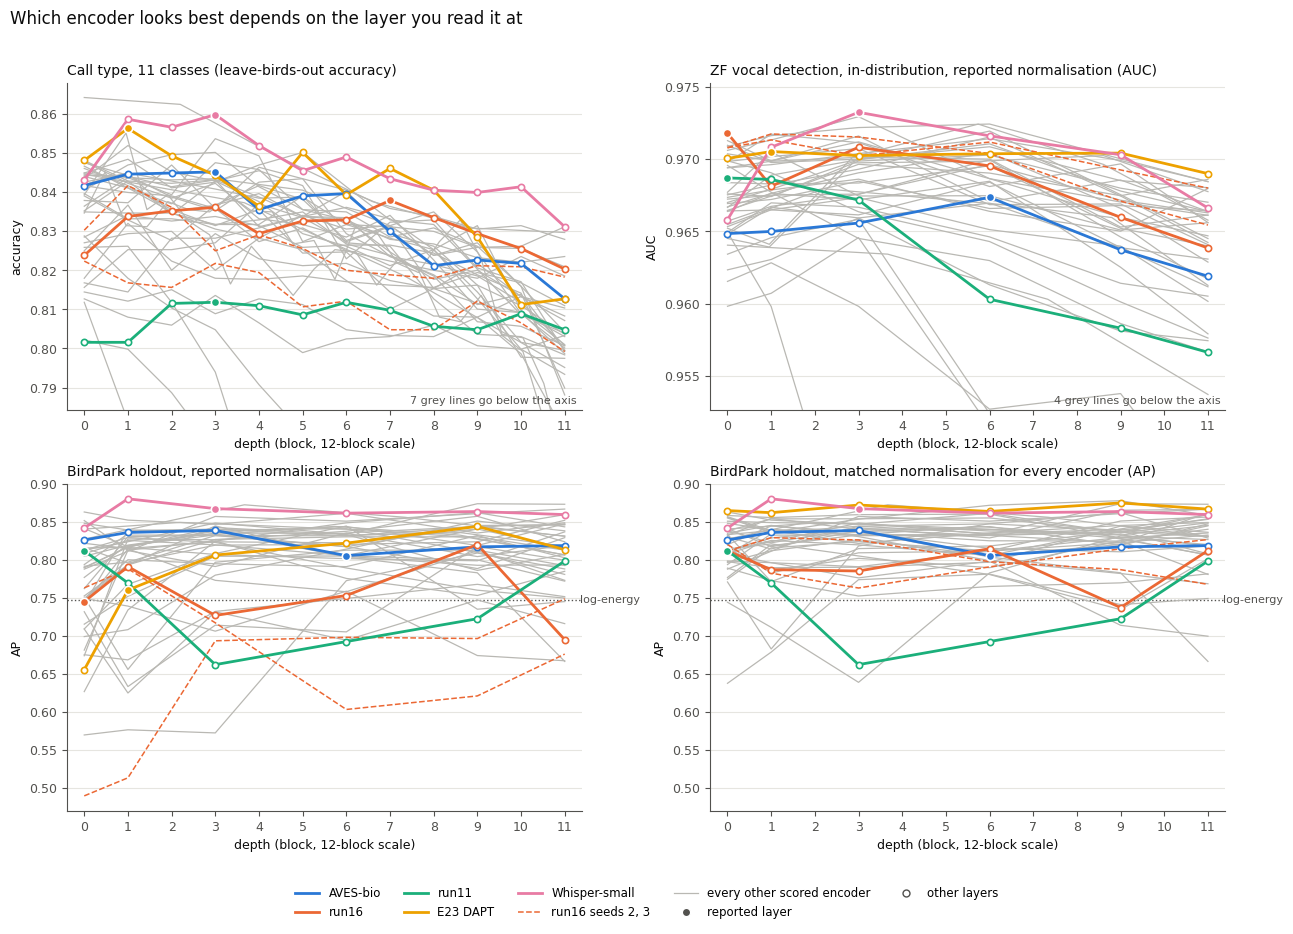

panel 1: below the axis -> ['birdaves-biox-large', 'birdaves-bioxn-large', 'daptv4aveso_2e4s2_step15000', 'hf-data2vec-audio-base', 'hf-hubert-base-ls960', 'hf-wav2vec2-base', 'hf-wavlm-base-plus']
panel 2: below the axis -> ['hf-data2vec-audio-base', 'hf-hubert-base-ls960', 'hf-wav2vec2-base', 'hf-wavlm-base-plus']


In [2]:
# Categorical slots 1-5 of the reference palette, in fixed order; context lines are one grey.
HL = [  # key, label, colour
    ("aves-base-bio",              "AVES-bio",       "#2a78d6"),
    ("run16_compute4x",            "run16",          "#eb6834"),
    ("run11",                      "run11",          "#1baf7a"),
    ("daptv4two_2e4s2_step15000",  "E23 DAPT",       "#eda100"),
    ("hf-whisper-small-enc",       "Whisper-small",  "#e87ba4"),
]
SEEDS = ["run16_seed2", "run16_seed3"]          # drawn in run16's colour, dashed
CONTEXT = "#b9b8b3"
INK, MUTED = "#0b0b0b", "#52514e"
HL_KEYS = {k for k, _, _ in HL} | set(SEEDS)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "font.size": 9})

fig, axes = plt.subplots(2, 2, figsize=(13, 9.2))
axes = axes.ravel()
panels = [
    ("Call type, 11 classes (leave-birds-out accuracy)", "accuracy"),
    ("ZF vocal detection, in-distribution, reported normalisation (AUC)", "AUC"),
    ("BirdPark holdout, reported normalisation (AP)", "AP"),
    ("BirdPark holdout, matched normalisation for every encoder (AP)", "AP"),
]

def series(m, panel):
    if panel == 0:
        a = CT[m]["acc"]; x = depth(len(a)); return x, a, CT[m]["best"]
    d = DET[m]
    n = len(CT[m]["acc"]) if m in CT else 12              # number of blocks, from call type
    x = np.array(d["layers"]) * 11 / (n - 1)
    i = d["layers"].index(d["chosen"])
    if panel == 1:
        return x, d["zf"], i
    if panel == 2:
        return x, d["bp"], i
    # panel 3: the same layers read with matched normalisation; the reported layer is marked only
    # when the reported arm was itself matched
    y = [D["zf_to_bp"][m][f"matched_L{l}"]["ap"] for l in d["layers"]]
    return x, y, (i if d["tag"] == "matched" else None)

def line(ax, x, y, chosen_idx, color, lw, ls="-", z=2, label=None, ms=4.5):
    ax.plot(x, y, ls, color=color, lw=lw, zorder=z, label=label)
    if ms:
        ax.plot(x, y, "o", ms=ms, mfc="white", mec=color, mew=1.2, zorder=z + 0.1, ls="none")
        if chosen_idx is not None:
            ax.plot([x[chosen_idx]], [y[chosen_idx]], "o", ms=ms + 1.5, color=color,
                    mec="white", mew=1.2, zorder=z + 0.2)

below = {}
for p, ax in enumerate(axes):
    pool = CT if p == 0 else DET
    for m in pool:                                        # grey context first
        if m in HL_KEYS:
            continue
        x, y, c = series(m, p)
        ax.plot(x, y, "-", color=CONTEXT, lw=0.9, zorder=1)
    for m in SEEDS:
        if m in pool:
            x, y, c = series(m, p)
            line(ax, x, y, c, "#eb6834", 1.1, ls="--", z=3, ms=0)
    for m, lab, col in HL:
        if m in pool:
            x, y, c = series(m, p)
            line(ax, x, y, c, col, 2.0, z=4, label=lab)
    if p >= 2:
        ax.axhline(ENERGY_BP_AP, color=MUTED, lw=1, ls=":", zorder=0)
        ax.text(11.35, ENERGY_BP_AP, "log-energy", color=MUTED, fontsize=8, va="center")
    if p < 2:
        # zoom on the reference encoders; say how many grey lines leave the axis below
        hl = np.concatenate([np.asarray(series(m, p)[1]) for m in HL_KEYS if m in pool])
        lo = hl.min() - (0.015 if p == 0 else 0.004)
        ax.set_ylim(lo, hl.max() + (0.008 if p == 0 else 0.002))
        below[p] = sorted(m for m in pool if min(series(m, p)[1]) < lo)
        if below[p]:
            ax.text(0.99, 0.02, f"{len(below[p])} grey lines go below the axis",
                    transform=ax.transAxes, ha="right", fontsize=8, color=MUTED)
    ax.set_title(panels[p][0], loc="left", fontsize=10, color=INK)
    ax.set_ylabel(panels[p][1]); ax.set_xlabel("depth (block, 12-block scale)")
    ax.set_xticks(range(0, 12)); ax.set_xlim(-0.4, 11.4)
    ax.yaxis.grid(True, color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
lo_bp = min(axes[2].get_ylim()[0], axes[3].get_ylim()[0])
for ax in axes[2:]:
    ax.set_ylim(lo_bp, 0.9)                              # same scale for the two BirdPark panels

from matplotlib.lines import Line2D
handles = [Line2D([], [], color=c, lw=2, label=l) for _, l, c in HL]
handles += [Line2D([], [], color="#eb6834", lw=1.1, ls="--", label="run16 seeds 2, 3"),
            Line2D([], [], color=CONTEXT, lw=0.9, label="every other scored encoder"),
            Line2D([], [], marker="o", ls="none", color=MUTED, mec="white", ms=6,
                   label="reported layer"),
            Line2D([], [], marker="o", ls="none", mfc="white", mec=MUTED, ms=5,
                   label="other layers")]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=8.5,
           bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Which encoder looks best depends on the layer you read it at", x=0.01, ha="left",
             fontsize=12, color=INK)
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
out = Path("figures"); out.mkdir(exist_ok=True)
fig.savefig(out / "07_layer_sweeps.png", dpi=150, bbox_inches="tight")
plt.show()
for p, ms in below.items():
    print(f"panel {p + 1}: below the axis -> {ms}")

## Call type: how big is the layer choice next to the gaps we argue about?

Three numbers per encoder, all from the per-layer call-type scores:

- **best** — the accuracy at its best layer, which is the reported headline (best layer on the
  same 5 folds, finding 035's caveat applies);
- **layer range** — best minus worst over its layers;
- **L3** — its accuracy at one fixed layer for everyone. Layer 3 is the label-free score's layer
  (finding 050), so it was not chosen to favour anyone.

The seed row is the yardstick: run16's three seeds differ only in the random seed, so their spread
at each layer is the smallest difference this instrument can call real for one run per arm.

In [3]:
names = {k: l for k, l, _ in HL}
rows = []
for m, v in CT.items():
    a = np.array(v["acc"])
    rows.append(dict(encoder=names.get(m, m), blocks=len(a), best_layer=v["best"], best=a.max(),
                     layer_range=a.max() - a.min(),
                     L3=a[3] if len(a) == 12 else np.nan))
T = pd.DataFrame(rows).sort_values("best", ascending=False).reset_index(drop=True)
T["rank_best"] = T.best.rank(ascending=False, method="min").astype(int)
T["rank_L3"] = T.L3.rank(ascending=False, method="min")
display(T.style.format({"best": "{:.4f}", "layer_range": "{:.4f}", "L3": "{:.4f}",
                        "rank_L3": "{:.0f}"}).hide(axis="index"))

seeds = np.array([CT[m]["acc"] for m in ("run16_compute4x", *SEEDS)])
seed_spread = seeds.max(0) - seeds.min(0)
print("run16 three-seed spread by layer:", " ".join(f"L{i}:{s:.4f}" for i, s in enumerate(seed_spread)))
print(f"  median {np.median(seed_spread):.4f}, max {seed_spread.max():.4f}")
twelve = T[T.blocks == 12]
print(f"\nlayer range across the {len(twelve)} 12-block encoders: "
      f"median {twelve.layer_range.median():.4f}, min {twelve.layer_range.min():.4f}, "
      f"max {twelve.layer_range.max():.4f}")
print(f"best-layer index across encoders: {T.best_layer.value_counts().sort_index().to_dict()}")

encoder,blocks,best_layer,best,layer_range,L3,rank_best,rank_L3
hf-whisper-base-enc,6,0,0.8643,0.0346,nan,1,nan
Whisper-small,12,3,0.8599,0.0287,0.8599,2,1
E23 DAPT,12,1,0.8564,0.0451,0.8444,3,6
birdaves-biox-large,24,2,0.8552,0.0856,nan,4,nan
daptv4two45k_2e4_step45000,12,3,0.8538,0.0528,0.8538,5,2
birdaves-biox-base,12,1,0.8520,0.0525,0.8429,6,10
aves-base-core,12,3,0.8502,0.0419,0.8502,7,3
daptv3aves_2e4_step15000,12,5,0.8502,0.0463,0.8426,7,12
daptv3aves_2e4s2m8_step15000,12,0,0.8482,0.0489,0.8429,9,10
aves-base-all,12,0,0.8479,0.0492,0.8423,10,13


run16 three-seed spread by layer: L0:0.0079 L1:0.0249 L2:0.0205 L3:0.0144 L4:0.0100 L5:0.0220 L6:0.0208 L7:0.0331 L8:0.0287 L9:0.0173 L10:0.0191 L11:0.0211
  median 0.0207, max 0.0331

layer range across the 39 12-block encoders: median 0.0419, min 0.0103, max 0.2814
best-layer index across encoders: {0: 15, 1: 10, 2: 4, 3: 8, 4: 3, 5: 2, 7: 1}


In [4]:
# Who is top at each layer? Only the 12-block encoders, so every layer index means the same block.
C12 = {m: np.array(v["acc"]) for m, v in CT.items() if len(v["acc"]) == 12}
M = pd.DataFrame(C12)
top = pd.DataFrame({"top encoder": M.idxmax(axis=1).map(lambda m: names.get(m, m)),
                    "acc": M.max(axis=1),
                    "runner-up": M.apply(lambda r: names.get(r.nlargest(2).index[1],
                                                             r.nlargest(2).index[1]), axis=1),
                    "gap to runner-up": M.apply(lambda r: r.nlargest(2).iloc[0] - r.nlargest(2).iloc[1],
                                                axis=1)})
top.index.name = "layer"
display(top.style.format({"acc": "{:.4f}", "gap to runner-up": "{:.4f}"}))
print(f"{top['top encoder'].nunique()} different encoders are top at some layer; "
      f"the gap to the runner-up is below run16's median seed spread at "
      f"{int((top['gap to runner-up'] < np.median(seed_spread)).sum())} of 12 layers.")

,top encoder,acc,runner-up,gap to runner-up
layer,,,,
0,daptv3aves_2e4s2m8_step15000,0.8482,E23 DAPT,0.0000
1,Whisper-small,0.8587,E23 DAPT,0.0023
2,Whisper-small,0.8567,aves-base-core,0.0070
3,Whisper-small,0.8599,daptv4two45k_2e4_step45000,0.0062
4,Whisper-small,0.8520,daptv4two45k_2e4_step45000,0.0026
5,daptv3aves_2e4_step15000,0.8502,E23 DAPT,0.0000
6,Whisper-small,0.8491,daptv3aves_2e4_step15000,0.0076
7,E23 DAPT,0.8461,Whisper-small,0.0026
8,E23 DAPT,0.8406,Whisper-small,0.0000


4 different encoders are top at some layer; the gap to the runner-up is below run16's median seed spread at 12 of 12 layers.


## Detection: the criterion is flat where the holdout moves

Two measurements per encoder, both read from the full arm grid (2 normalisations x its layer grid):

- **046's measure, extended to every encoder**: take the three arms with the highest in-distribution
  ZF AUC; report their spread in ZF AUC and their spread in BirdPark AP. 046 did this for four
  models; this is all of them.
- **Reported arm vs the rest**: where the ZF-chosen arm's BirdPark AP ranks among all arms. It
  should not be expected to rank first (choosing on BirdPark would be choosing on the test set); the
  point is how far below the best arm it can sit by luck.

The BirdPark maximum is printed to show the selection risk only; it is a maximum over the test set
and never a result.

In [5]:
rows = []
for m, d in DET.items():
    arms = {k: (D["in_distribution"][m][k]["auc"], D["zf_to_bp"][m][k]["ap"])
            for k in D["in_distribution"][m]}
    top3 = sorted(arms, key=lambda k: -arms[k][0])[:3]
    zf3 = np.array([arms[k][0] for k in top3]); bp3 = np.array([arms[k][1] for k in top3])
    rep = f"{d['tag']}_L{d['chosen']}"
    bp_all = np.array([v[1] for v in arms.values()])
    rows.append(dict(encoder=names.get(m, m), arm=rep,
                     top3_zf_auc_spread=zf3.max() - zf3.min(), top3_bp_ap_spread=bp3.max() - bp3.min(),
                     bp_ap_reported=arms[rep][1], bp_ap_posthoc_max=bp_all.max(),
                     reported_rank=int((bp_all > arms[rep][1]).sum()) + 1, n_arms=len(arms)))
S = pd.DataFrame(rows)
S["amplification"] = S.top3_bp_ap_spread / S.top3_zf_auc_spread
S = S.sort_values("bp_ap_reported", ascending=False).reset_index(drop=True)
display(S.style.format({"top3_zf_auc_spread": "{:.4f}", "top3_bp_ap_spread": "{:.4f}",
                        "bp_ap_reported": "{:.4f}", "bp_ap_posthoc_max": "{:.4f}",
                        "amplification": "{:.0f}x"}).hide(axis="index"))
print(f"over {len(S)} encoders, top-3 arms: median ZF AUC spread {S.top3_zf_auc_spread.median():.4f}, "
      f"median BirdPark AP spread {S.top3_bp_ap_spread.median():.4f}, "
      f"median amplification {S.amplification.median():.0f}x "
      f"(IQR {S.amplification.quantile(.25):.0f}x-{S.amplification.quantile(.75):.0f}x)")
print(f"reported arm is the BirdPark-best arm for {int((S.reported_rank == 1).sum())} of {len(S)}; "
      f"median rank {S.reported_rank.median():.0f} of {int(S.n_arms.median())}; "
      f"median gap to the post-hoc best {(S.bp_ap_posthoc_max - S.bp_ap_reported).median():.4f} AP")
b = D["bootstrap"]["run11_vs_logenergy"]["bp_ap_block1500"]
print(f"for scale: run11 vs log-energy on BirdPark AP, 95% interval [{b['lo']:+.4f}, {b['hi']:+.4f}] "
      f"({b['verdict']})")

# The seed yardstick on BirdPark: run16's three seeds at each layer, per normalisation
print("\nrun16 three-seed spread in BirdPark AP, by layer:")
for tag in ("native", "matched"):
    v = np.array([[D["zf_to_bp"][m][f"{tag}_L{l}"]["ap"] for l in D["layer_grids"][m]]
                  for m in ("run16_compute4x", *SEEDS)])
    sp = v.max(0) - v.min(0)
    print(f"  {tag:8s}" + " ".join(f"L{l}:{x:.3f}" for l, x in zip(D["layer_grids"]["run16_compute4x"], sp))
          + f"   median {np.median(sp):.3f}")
tags = pd.Series({m: d["tag"] for m, d in DET.items()}).value_counts().to_dict()
print(f"\nreported normalisation across the {len(DET)} encoders: {tags}")

encoder,arm,top3_zf_auc_spread,top3_bp_ap_spread,bp_ap_reported,bp_ap_posthoc_max,reported_rank,n_arms,amplification
Whisper-small,matched_L3,0.0019,0.0461,0.8677,0.8807,2,12,24x
hf-whisper-base-enc,matched_L1,0.0013,0.0367,0.8496,0.8496,1,10,28x
daptv4two_2e4_step15000,native_L6,0.0008,0.1149,0.8490,0.8782,7,12,143x
daptv3aves_2e4s2_step15000,matched_L3,0.0003,0.0203,0.8471,0.8633,5,12,68x
birdaves-bioxn-large,matched_L12,0.0023,0.0114,0.8442,0.8442,1,12,5x
daptv3aves_2e4_step15000,matched_L6,0.0010,0.0821,0.8441,0.8484,3,12,82x
hf-hubert-base-ls960,native_L3,0.0017,0.0193,0.8395,0.8449,3,12,12x
birdaves-biox-large,matched_L18,0.0003,0.0211,0.8362,0.8366,2,12,61x
daptv4aveso_2e4s2_step15000,native_L6,0.0004,0.0253,0.8351,0.8604,7,12,61x
daptv4bird_2e4_step15000,matched_L6,0.0007,0.0317,0.8339,0.8742,5,12,45x


over 44 encoders, top-3 arms: median ZF AUC spread 0.0011, median BirdPark AP spread 0.0456, median amplification 45x (IQR 23x-86x)
reported arm is the BirdPark-best arm for 3 of 44; median rank 6 of 12; median gap to the post-hoc best 0.0338 AP
for scale: run11 vs log-energy on BirdPark AP, 95% interval [-0.0003, +0.1208] (not_distinguishable)

run16 three-seed spread in BirdPark AP, by layer:
  native  L0:0.274 L1:0.278 L3:0.033 L6:0.150 L9:0.200 L11:0.073   median 0.175
  matched L0:0.008 L1:0.047 L3:0.063 L6:0.024 L9:0.077 L11:0.059   median 0.053

reported normalisation across the 44 encoders: {'native': 31, 'matched': 13}


## What this does and does not license

**Supported.** The pictures restate existing findings; they add no new claim. Read them as
instrument checks:

- On call type, an encoder's own layer curve and the gaps between the leading encoders are of the
  same order as the seed spread of a single recipe. A one-seed, best-layer ranking among the top
  encoders is not a ranking (057, 062, 070).
- On detection, the in-distribution criterion barely moves across layers while BirdPark AP moves a
  lot, for nearly every encoder, not only the DAPT checkpoints of 046. The ZF-chosen layer is rarely
  the BirdPark-best layer, and it should not be: choosing the layer on BirdPark would be choosing on
  the test set.
- Most of the BirdPark scatter comes from the input normalisation, not from depth. The selection rule
  picks raw waveform ('native') for most encoders, and under native input run16's three seeds
  disagree by several times more than under matched input (printed above; bottom-right panel against
  bottom-left). This is finding 049's lever, and the reason backlog item T4 proposes matched input
  as the BirdPark headline.

**Not supported.** Nothing here ranks two encoders. Those comparisons are made with paired bird
bootstraps (call type) and block bootstraps (detection) at the pre-committed arm, in the findings.
The grey lines are context, not a population: they are whichever encoders happened to be scored,
many of them variants of one another.

Sources: `aves_variants_calltype.json`, `<tag>_calltype.json` (per_layer_acc11 / best_layer11),
`detection_variants.json` (precommit.joint, in_distribution, zf_to_bp, layer_grids,
bootstrap.run11_vs_logenergy), all under `~/zf_labelset/zf_detection_dataset_v1/analysis/`.